In [3]:
import pandas as pd

# Cleaning teams_post

In [2]:
teams_post = pd.read_csv("basketballPlayoffs/teams_post.csv")

columns_to_drop = ['lgID']
teams_post_cleaned = teams_post.drop(columns=columns_to_drop)
teams_post_cleaned.head()

,year,tmID,W,L
0,1,HOU,6,0
1,1,ORL,1,2
2,1,CLE,3,3
3,1,WAS,0,2
4,1,NYL,4,3


In [3]:
teams_post_cleaned.to_csv('cleaned_datasets/teams_post_cleaned.csv', index=False)

# Cleaning series_post

In [4]:
series_post = pd.read_csv("basketballPlayoffs/series_post.csv")

columns_to_drop = ['lgIDWinner', 'lgIDLoser']
series_post_cleaned = series_post.drop(columns=columns_to_drop)
series_post_cleaned.head()

,year,round,series,tmIDWinner,tmIDLoser,W,L
0,1,FR,A,CLE,ORL,2,1
1,1,FR,B,NYL,WAS,2,0
2,1,FR,C,LAS,PHO,2,0
3,1,FR,D,HOU,SAC,2,0
4,1,CF,E,HOU,LAS,2,0


In [5]:
series_post_cleaned.to_csv('cleaned_datasets/series_post_cleaned.csv', index=False)

# Cleaning awards_players

In [13]:
awards_players = pd.read_csv("basketballPlayoffs/awards_players.csv")

# Agrupar os dados por playerID e award, e contar quantas vezes cada combinação aparece
awards_players_cleaned = awards_players.groupby(['playerID', 'award']).size().reset_index(name='trophy_count')

# Exibir o resultado final
awards_players_cleaned.head()

,playerID,award,trophy_count
0,arcaija01w,Most Improved Player,1
1,augusse01w,Rookie of the Year,1
2,beviltu01w,Kim Perrot Sportsmanship Award,1
3,birdsu01w,WNBA All-Decade Team,1
4,blackde01w,Defensive Player of the Year,1


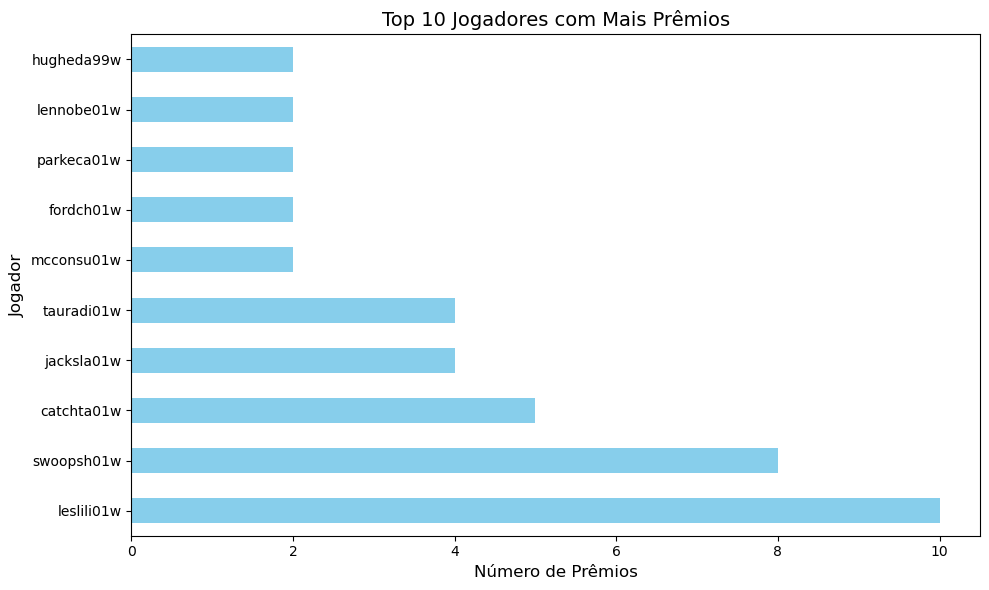

In [7]:
# Importar a biblioteca matplotlib
import matplotlib.pyplot as plt

# Ordenar os dados pelos jogadores com mais prêmios
top_players = awards_players_cleaned.groupby('playerID')['trophy_count'].sum().sort_values(ascending=False).head(10)

# Criar o gráfico de barras horizontais
plt.figure(figsize=(10,6))
top_players.plot(kind='barh', color='skyblue')

# Adicionar títulos e rótulos
plt.title('Top 10 Jogadores com Mais Prêmios', fontsize=14)
plt.xlabel('Número de Prêmios', fontsize=12)
plt.ylabel('Jogador', fontsize=12)

# Exibir o gráfico
plt.tight_layout()
plt.show()


In [14]:
awards_players_cleaned.to_csv('cleaned_datasets/awards_players_cleaned.csv', index=False)

In [22]:
player_awards = pd.read_csv("basketballPlayoffs/awards_players.csv")

award_values = {
    "Most Valuable Player": 10,
    "WNBA Finals Most Valuable Player": 9,
    "Coach of the Year": 1,
    "Defensive Player of the Year": 7,
    "All-Star Game Most Valuable Player": 6,
    "WNBA All-Decade Team": 5,
    "Most Improved Player": 4,
    "WNBA All Decade Team Honorable Mention": 3,
    "Rookie of the Year": 2,
    "Sixth Woman of the Year": 1,
    "Kim Perrot Sportsmanship Award": 0,  # irrelevant for winning
}


player_awards['trophyPower'] = 0
for player_id in player_awards['playerID'].unique():
    player_data = player_awards[player_awards['playerID'] == player_id]
    player_data = player_data.sort_values(by='year')
    
    previous_power = 0
    
    for index, row in player_data.iterrows():
        award = row['award']
        award_value = award_values.get(award, 0)
        current_power = previous_power + award_value
        player_awards.loc[index, 'trophyPower'] = current_power
        previous_power = current_power
player_awards = player_awards.drop(columns=['award', 'lgID'])
final_output = player_awards[['playerID', 'year', 'trophyPower']]
final_output = final_output.groupby(['playerID', 'year'], as_index=False)['trophyPower'].max()
final_output.to_csv('cleaned_datasets/awards_players_cleaned.csv', index=False)

print(final_output.head())


     playerID  year  trophyPower
0  arcaija01w     2            4
1  augusse01w     7            2
2  beviltu01w     8            0
3   birdsu01w     7            5
4  blackde01w     2            7


# Cleaning coaches

In [9]:
coaches = pd.read_csv("basketballPlayoffs/coaches.csv")

columns_to_drop = ['lgID']
coaches_cleaned = coaches.drop(columns=columns_to_drop)
coaches_cleaned.head()

,coachID,year,tmID,stint,won,lost,post_wins,post_losses
0,adamsmi01w,5,WAS,0,17,17,1,2
1,adubari99w,1,NYL,0,20,12,4,3
2,adubari99w,2,NYL,0,21,11,3,3
3,adubari99w,3,NYL,0,18,14,4,4
4,adubari99w,4,NYL,0,16,18,0,0


In [10]:
coaches_cleaned.to_csv('cleaned_datasets/coaches_cleaned.csv', index=False)

# Cleaning players

In [11]:
players = pd.read_csv("basketballPlayoffs/players.csv")

# Drop rows where birthDate is '0000-00-00' and where deathDate is not '0000-00-00'.
players_cleaned = players[(players['birthDate'] != '0000-00-00') & (players['deathDate'] == '0000-00-00')]

# Drop the 'firstseason' and 'lastseason' columns.
players_cleaned = players_cleaned.drop(columns=['firstseason', 'lastseason'])

# Display the first few rows to confirm the changes
players_cleaned.head()


,bioID,pos,height,weight,college,collegeOther,birthDate,deathDate
0,abrahta01w,C,74.0,190,George Washington,NaN,1975-09-27,0000-00-00
1,abrossv01w,F,74.0,169,Connecticut,NaN,1980-07-09,0000-00-00
2,adairje01w,C,76.0,197,George Washington,NaN,1986-12-19,0000-00-00
3,adamsda01w,F-C,73.0,239,Texas A&M,Jefferson College (JC),1989-02-19,0000-00-00
4,adamsjo01w,C,75.0,180,New Mexico,NaN,1981-05-24,0000-00-00


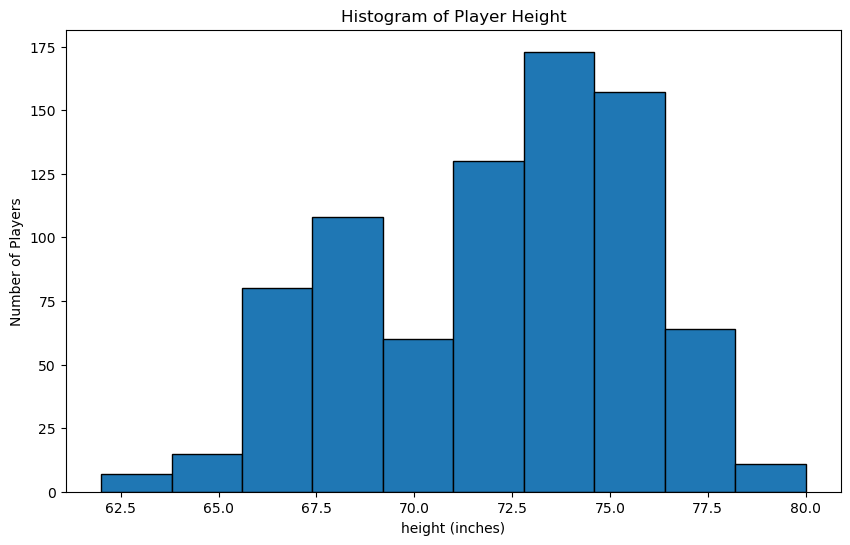

In [12]:
plt.figure(figsize=(10, 6))
plt.hist(players_cleaned['height'], bins=10, edgecolor='black')

# Add labels and title
plt.xlabel('height (inches)')
plt.ylabel('Number of Players')
plt.title('Histogram of Player Height')

# Show the plot
plt.show()

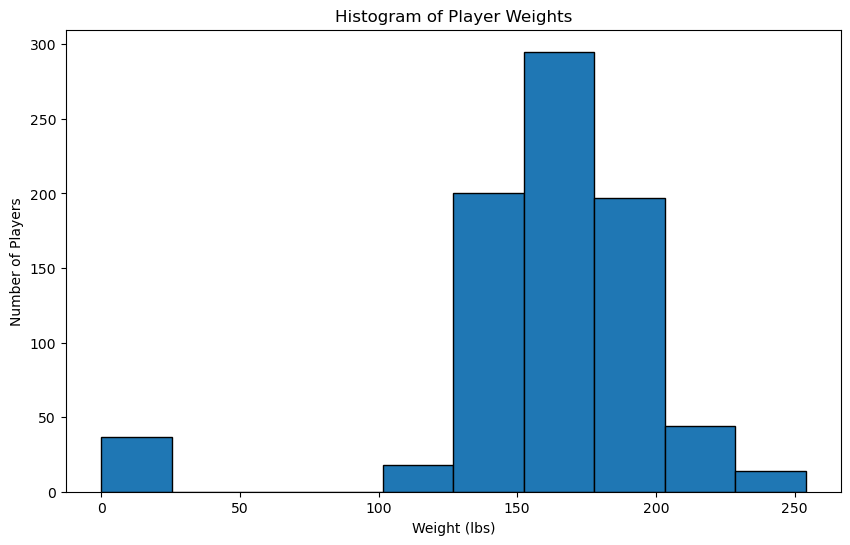

In [13]:
plt.figure(figsize=(10, 6))
plt.hist(players_cleaned['weight'], bins=10, edgecolor='black')

# Add labels and title
plt.xlabel('Weight (lbs)')
plt.ylabel('Number of Players')
plt.title('Histogram of Player Weights')

# Show the plot
plt.show()

In [14]:
average_weight_individual_pos = players_cleaned.groupby('pos')['weight'].mean().to_dict()

# Function to calculate the average weight for combined positions
def calculate_combined_pos_avg(pos):
    if '-' in pos:
        # Split the position (e.g., 'C-F') and calculate the average of the individual positions
        sub_positions = pos.split('-')
        weights = [average_weight_individual_pos[sub_pos] for sub_pos in sub_positions if sub_pos in average_weight_individual_pos]
        return sum(weights) / len(weights) if weights else None
    else:
        # If it's a single position, return the average directly
        return average_weight_individual_pos.get(pos, None)

# Apply the function to all positions in the dataset
players_cleaned['calculated_avg_weight'] = players_cleaned['pos'].apply(calculate_combined_pos_avg)

players_cleaned['weight'] = players_cleaned.apply(
    lambda row: row['calculated_avg_weight'] if row['weight'] < 50 else row['weight'], axis=1
)

players_cleaned[['bioID', 'pos', 'weight', 'calculated_avg_weight']].head()

# Display the results
print(players_cleaned[['pos', 'calculated_avg_weight']].drop_duplicates())

     pos  calculated_avg_weight
0      C             181.503876
1      F             166.403509
3    F-C             173.953692
8      G             143.628289
13   F-G             155.015899
29   G-F             155.015899
238  C-F             173.953692


In [15]:
# Drop the 'calculated_avg_weight' column and round the 'weight' to one decimal place
players_cleaned = players_cleaned.drop(columns=['calculated_avg_weight'])
players_cleaned['weight'] = players_cleaned['weight'].round(1)

players_cleaned.to_csv('cleaned_datasets/players_cleaned.csv', index=False)




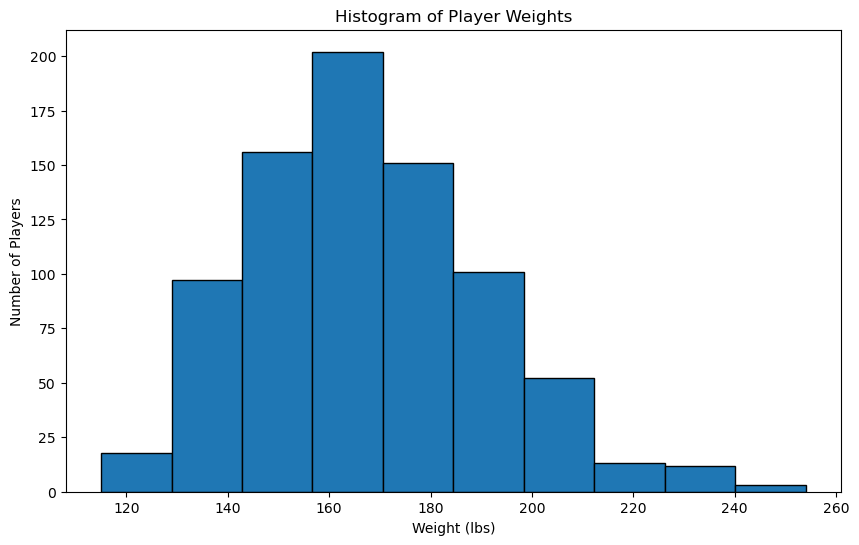

In [16]:
plt.figure(figsize=(10, 6))
plt.hist(players_cleaned['weight'], bins=10, edgecolor='black')

# Add labels and title
plt.xlabel('Weight (lbs)')
plt.ylabel('Number of Players')
plt.title('Histogram of Player Weights')

# Show the plot
plt.show()

In [17]:
columns_to_drop = ['birthDate', 'deathDate', 'weight', 'height']
players_cleaned = players_cleaned.drop(columns=columns_to_drop)
players_cleaned.head()

,bioID,pos,college,collegeOther
0,abrahta01w,C,George Washington,NaN
1,abrossv01w,F,Connecticut,NaN
2,adairje01w,C,George Washington,NaN
3,adamsda01w,F-C,Texas A&M,Jefferson College (JC)
4,adamsjo01w,C,New Mexico,NaN


In [18]:
players_cleaned.to_csv('cleaned_datasets/players_cleaned.csv', index=False)

# Analysing Teams Dataset

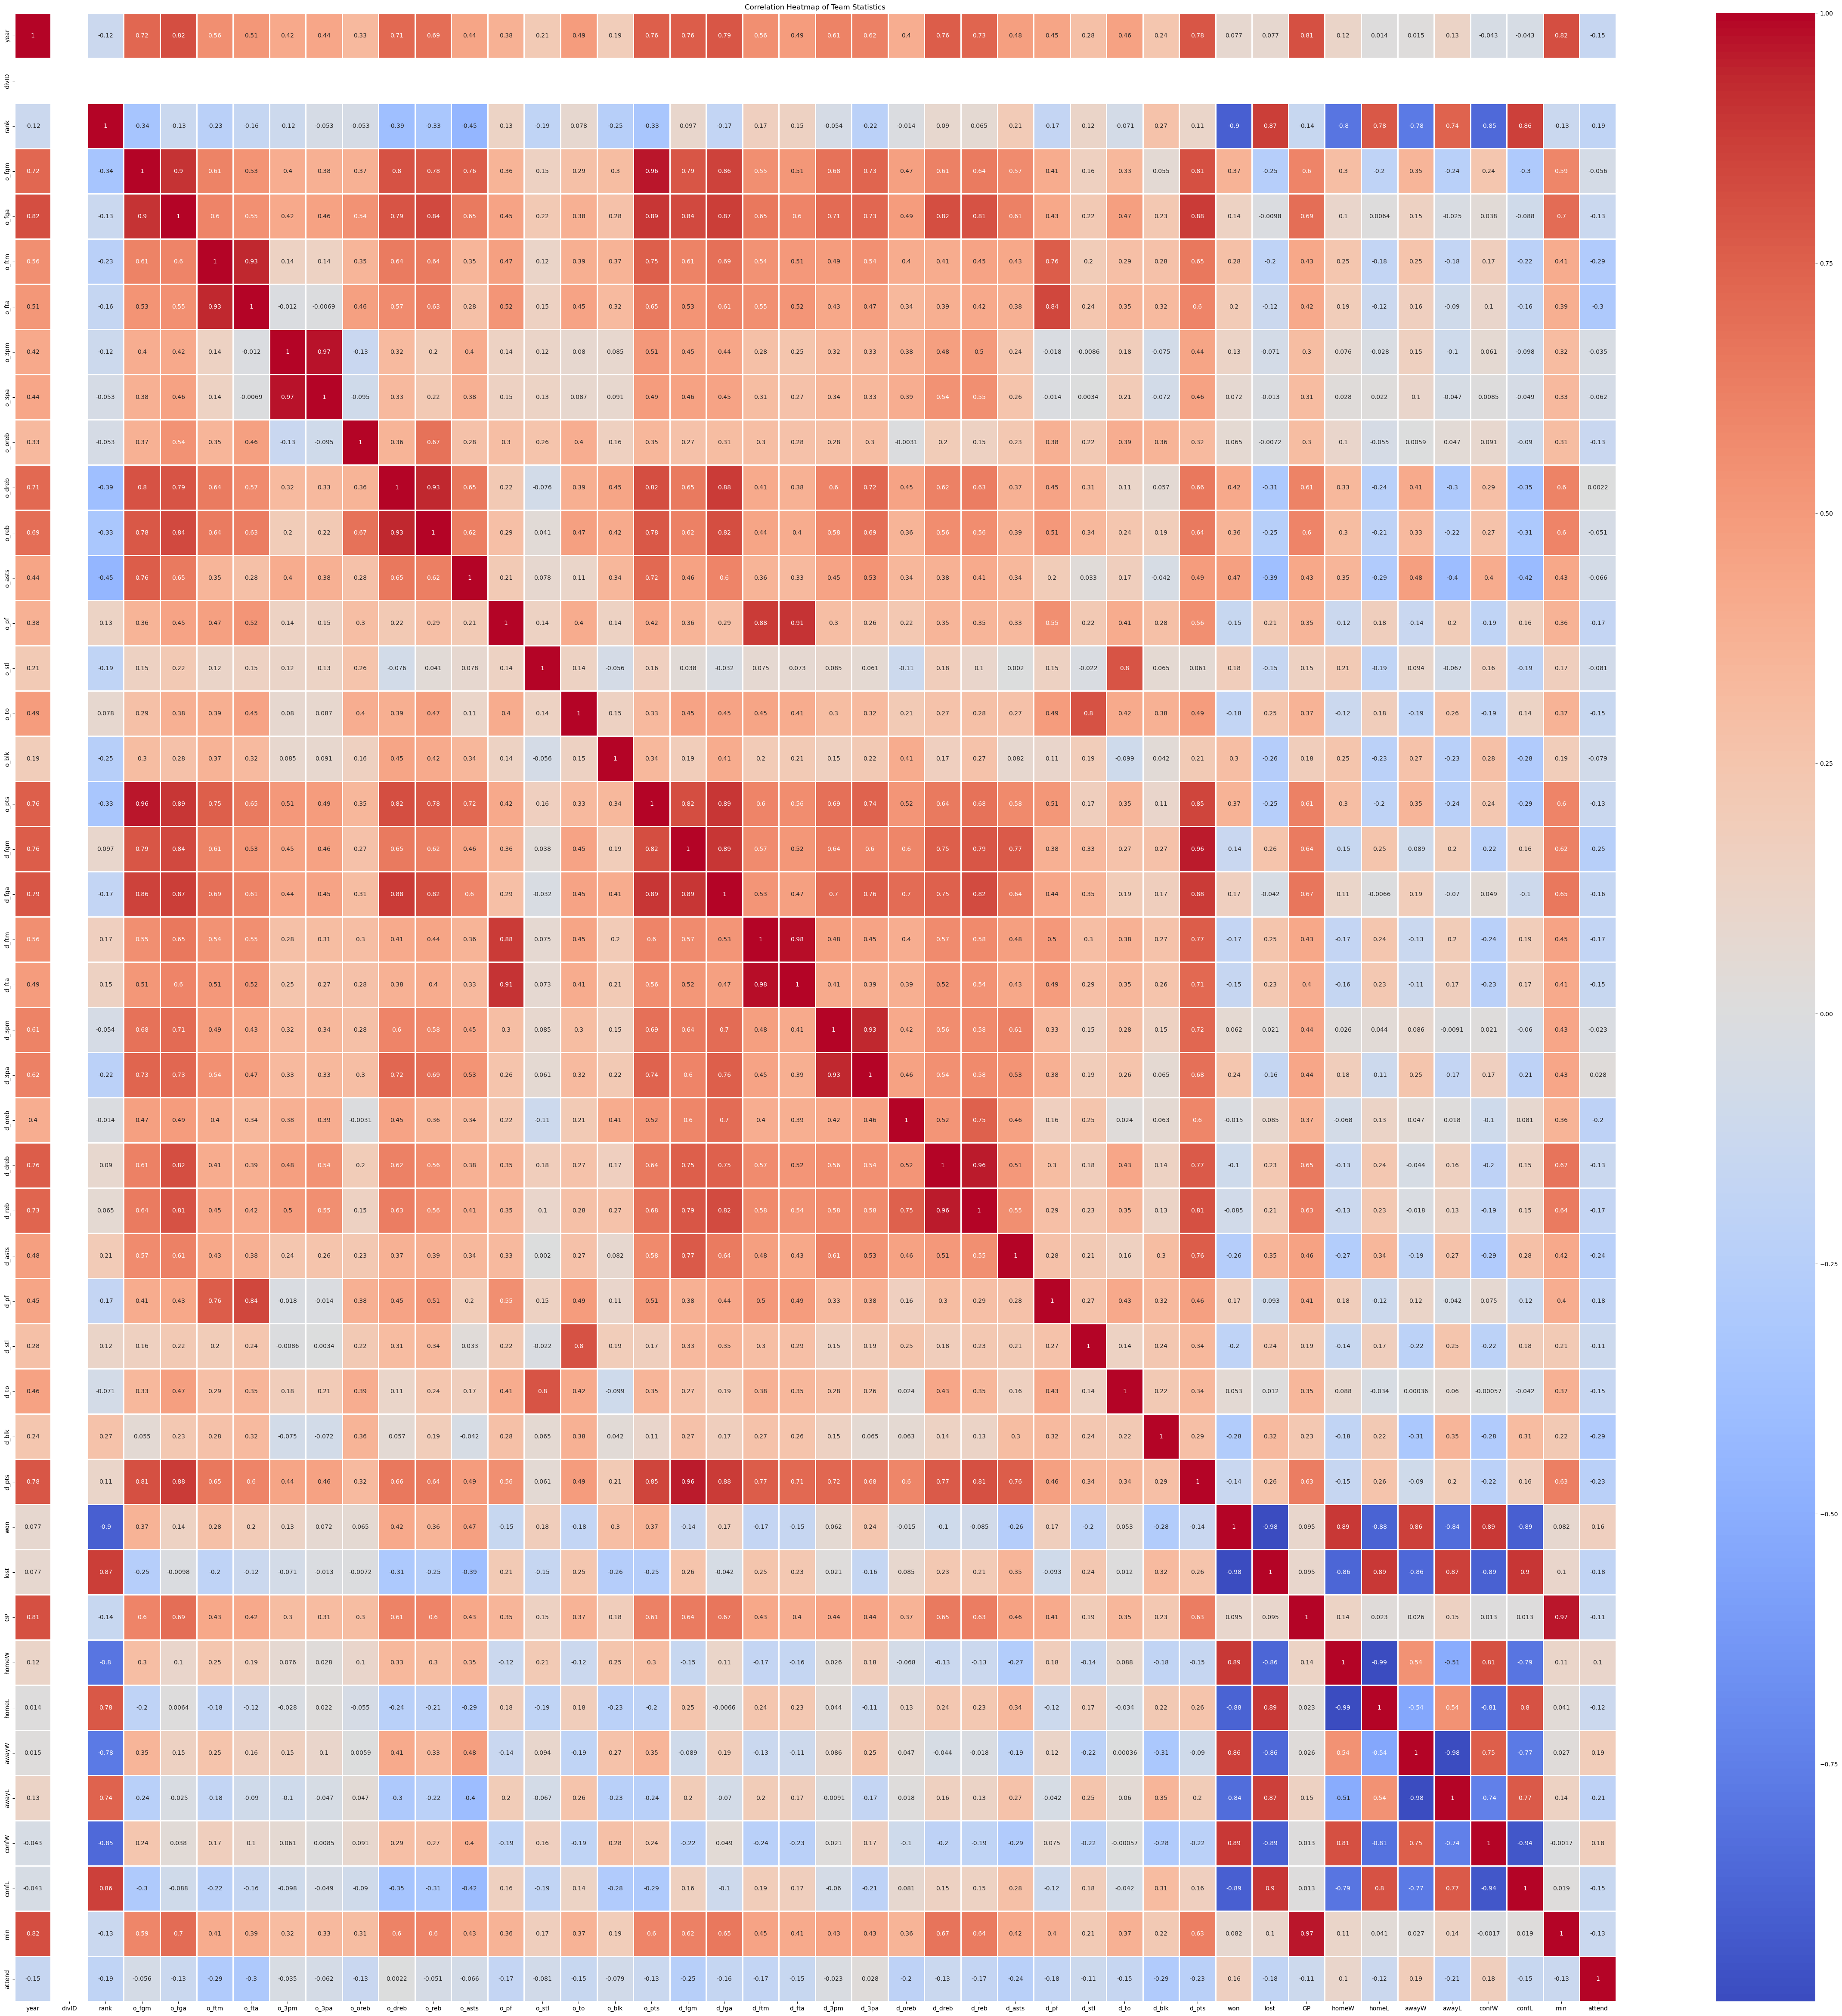

In [63]:


df = pd.read_csv("basketballPlayoffs/teams.csv")
# https://pythonguides.com/drop-non-numeric-columns-from-pandas-dataframe/

df = df.loc[:, (df != 0).any(axis=0)] # Eliminar Noisy Columns (que so têm 0)


data_numeric=df.select_dtypes(['number'])
correlation_matrix = data_numeric.corr()

plt.figure(figsize=(60, 60))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", linewidths=1)
plt.title("Correlation Heatmap of Team Statistics")
plt.show()


In [34]:
import plotly.express as px

df['PPG'] = df['o_pts'] / df['GP']
fig = px.line(df, x='year', y='PPG', color='name', markers=True,  hover_data={'year': True, 'PPG': True, 'won': True, 'lost': True, 'GP': True}, title="Points Per Game (PPG) Over Years by Team")
fig.update_layout(xaxis_title="Year",yaxis_title="Points Per Game (PPG)",legend_title="Team Name")
fig.show()


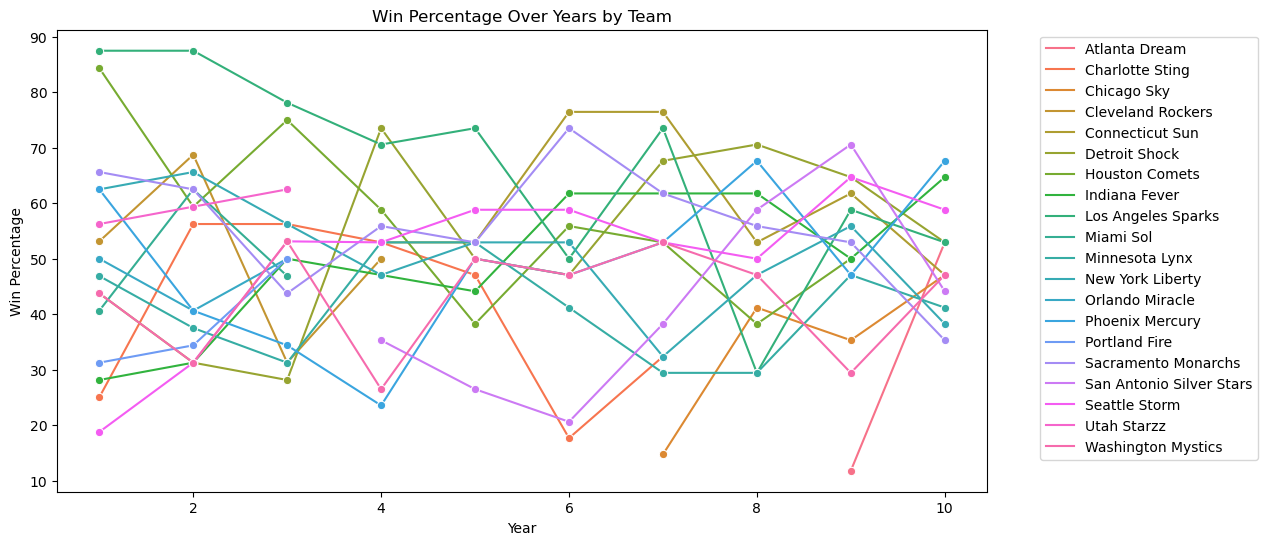

In [27]:

df['Win_Percentage'] = df['won'] / df['GP'] * 100
plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x='year', y='Win_Percentage', hue='name', marker="o")
plt.title("Win Percentage Over Years by Team")
plt.xlabel("Year")
plt.ylabel("Win Percentage")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()


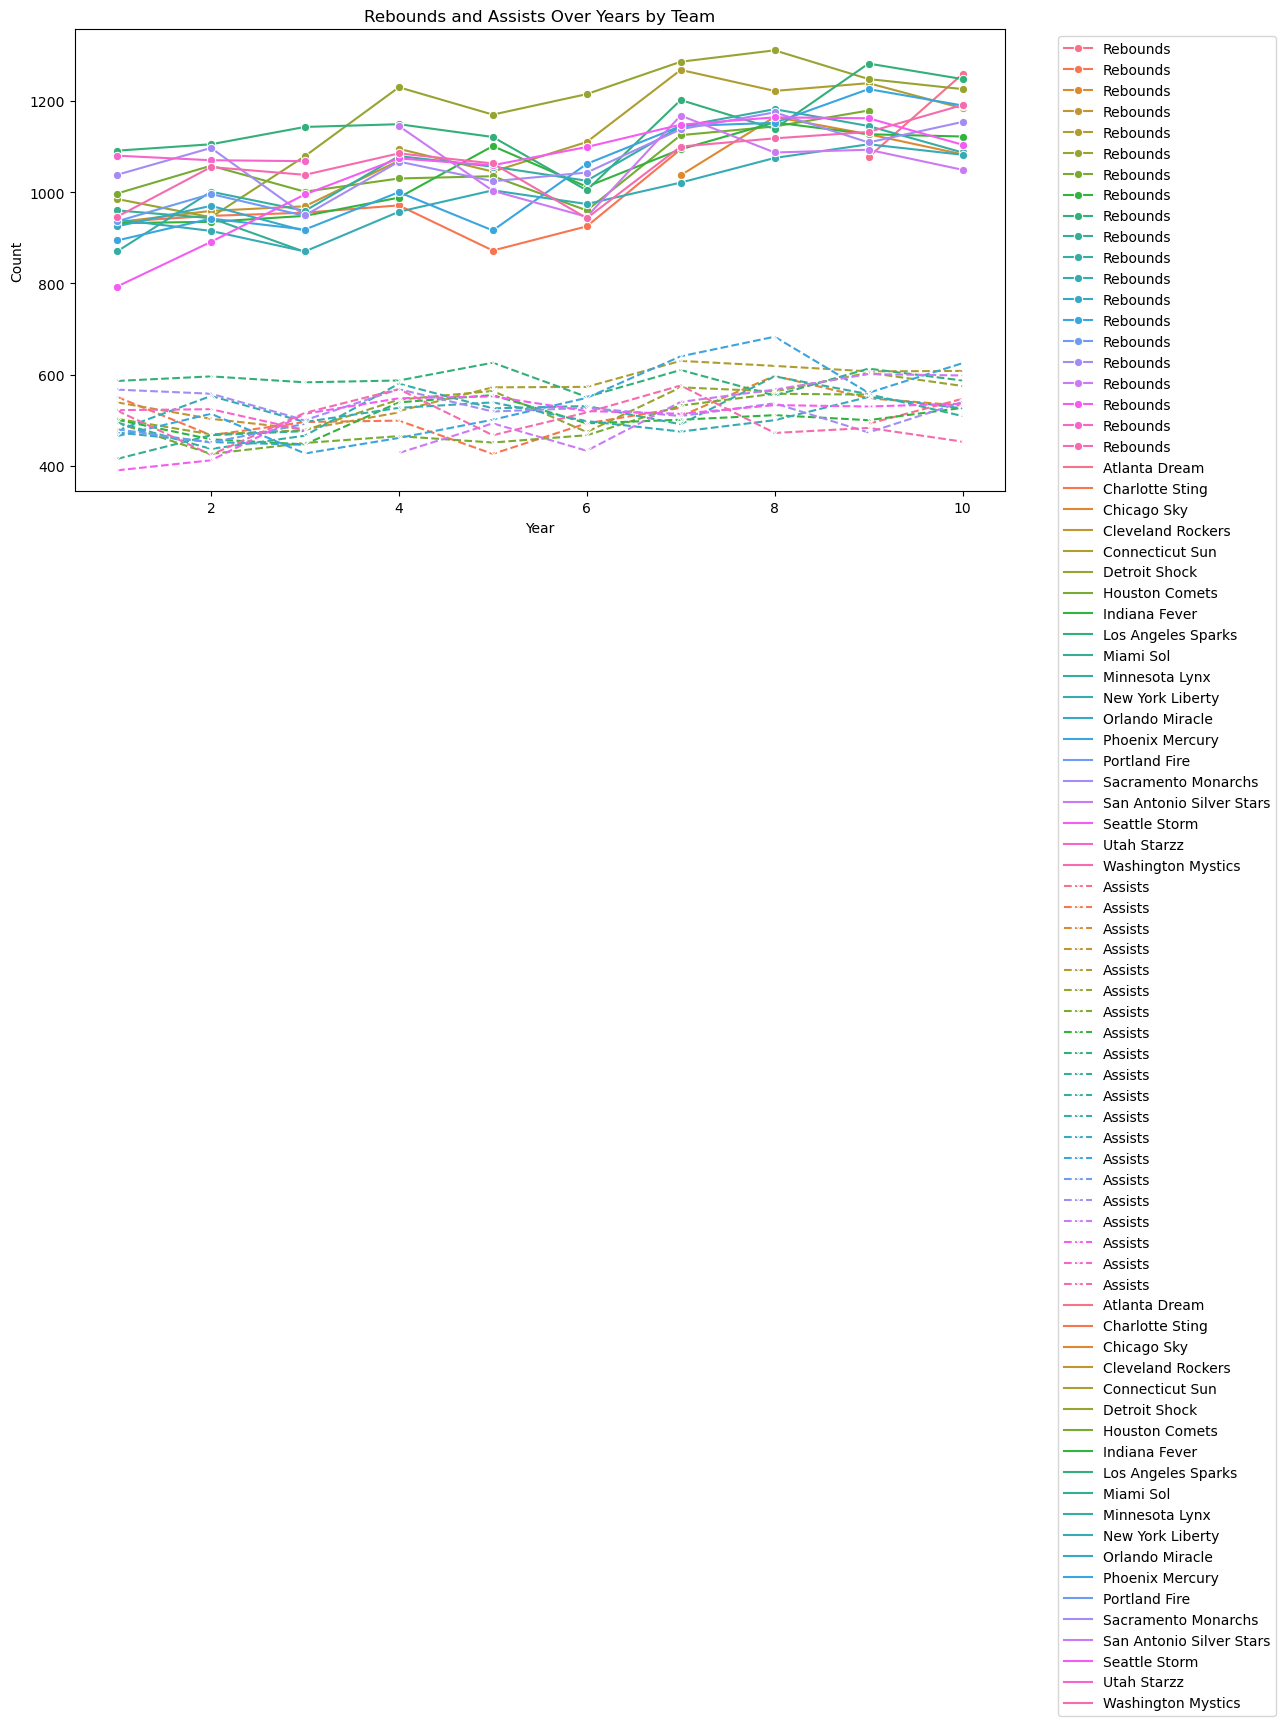

In [29]:

plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x='year', y='o_reb', hue='name', marker="o", label="Rebounds")
sns.lineplot(data=df, x='year', y='o_asts', hue='name', marker="x", linestyle="--", label="Assists")
plt.title("Rebounds and Assists Over Years by Team")
plt.xlabel("Year")
plt.ylabel("Count")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()


In [1]:
df['Home_Win_Percentage'] = df['homeW'] / (df['homeW'] + df['homeL']) * 100
df['Away_Win_Percentage'] = df['awayW'] / (df['awayW'] + df['awayL']) * 100
fig = px.scatter(df, x='Home_Win_Percentage',  y='Away_Win_Percentage', color='name', hover_data=['year', 'won', 'lost', 'GP'])
fig.update_layout(xaxis_title="Home Win Percentage",yaxis_title="Away Win Percentage",legend_title="Team Name")
fig.show()


NameError: name 'df' is not defined

In [37]:
fig = px.line(df, x='year', y='attend', color='name', markers=True,  hover_data={'year': True, 'attend': True, 'name': True},  title="Attendance Over Years by Team")
fig.update_layout(xaxis_title="Year",yaxis_title="Attendance",legend_title="Team Name")
fig.show()

## Attendence ate pode ser importante porque mostra equipas que estao a ficar na moda tipo ?


In [47]:
# Teams playing per year

teams_per_year = df.groupby('year')['tmID'].nunique()
print(teams_per_year)

print('\n')


 # List Teams That Qualify For Offs and the Respective Winner for each year
playoff_teams = df[(df['year'].between(1, 10)) & (df['playoff'] == "Y")]

teams_by_year = {}
for year, group in playoff_teams.groupby('year'):
    teams = group['name'].tolist()
    winner = group.loc[group['finals'] == "W", 'name'].tolist()
    winning_team = winner[0] if winner else "No winner listed"
    teams_by_year[year] = {
        "teams": teams,
        "winner": winning_team
    }
for year, info in teams_by_year.items():
    print(f"Year {year}: Teams - {info['teams']}, Winner - {info['winner']}")


# Fica para pensar adicionar uma coluna nas equipas em que ponho "won last year" porque se ganhou as finals é muito provavel que no ano seguinte esteja automaticamente nos offs, isso confirma-se em praticamente todos os anos da lista
# É uma prediction automatica



year
1     16
2     16
3     16
4     14
5     13
6     13
7     14
8     13
9     14
10    13
Name: tmID, dtype: int64


Year 1: Teams - ['Cleveland Rockers', 'Houston Comets', 'Los Angeles Sparks', 'New York Liberty', 'Orlando Miracle', 'Phoenix Mercury', 'Sacramento Monarchs', 'Washington Mystics'], Winner - Houston Comets
Year 2: Teams - ['Charlotte Sting', 'Cleveland Rockers', 'Houston Comets', 'Los Angeles Sparks', 'Miami Sol', 'New York Liberty', 'Sacramento Monarchs', 'Utah Starzz'], Winner - Los Angeles Sparks
Year 3: Teams - ['Charlotte Sting', 'Houston Comets', 'Indiana Fever', 'Los Angeles Sparks', 'New York Liberty', 'Seattle Storm', 'Utah Starzz', 'Washington Mystics'], Winner - Los Angeles Sparks
Year 4: Teams - ['Charlotte Sting', 'Cleveland Rockers', 'Connecticut Sun', 'Detroit Shock', 'Houston Comets', 'Los Angeles Sparks', 'Minnesota Lynx', 'Sacramento Monarchs'], Winner - Detroit Shock
Year 5: Teams - ['Connecticut Sun', 'Detroit Shock', 'Los Angeles Sparks', 'Minne

# Analysing Player_Teams CSV


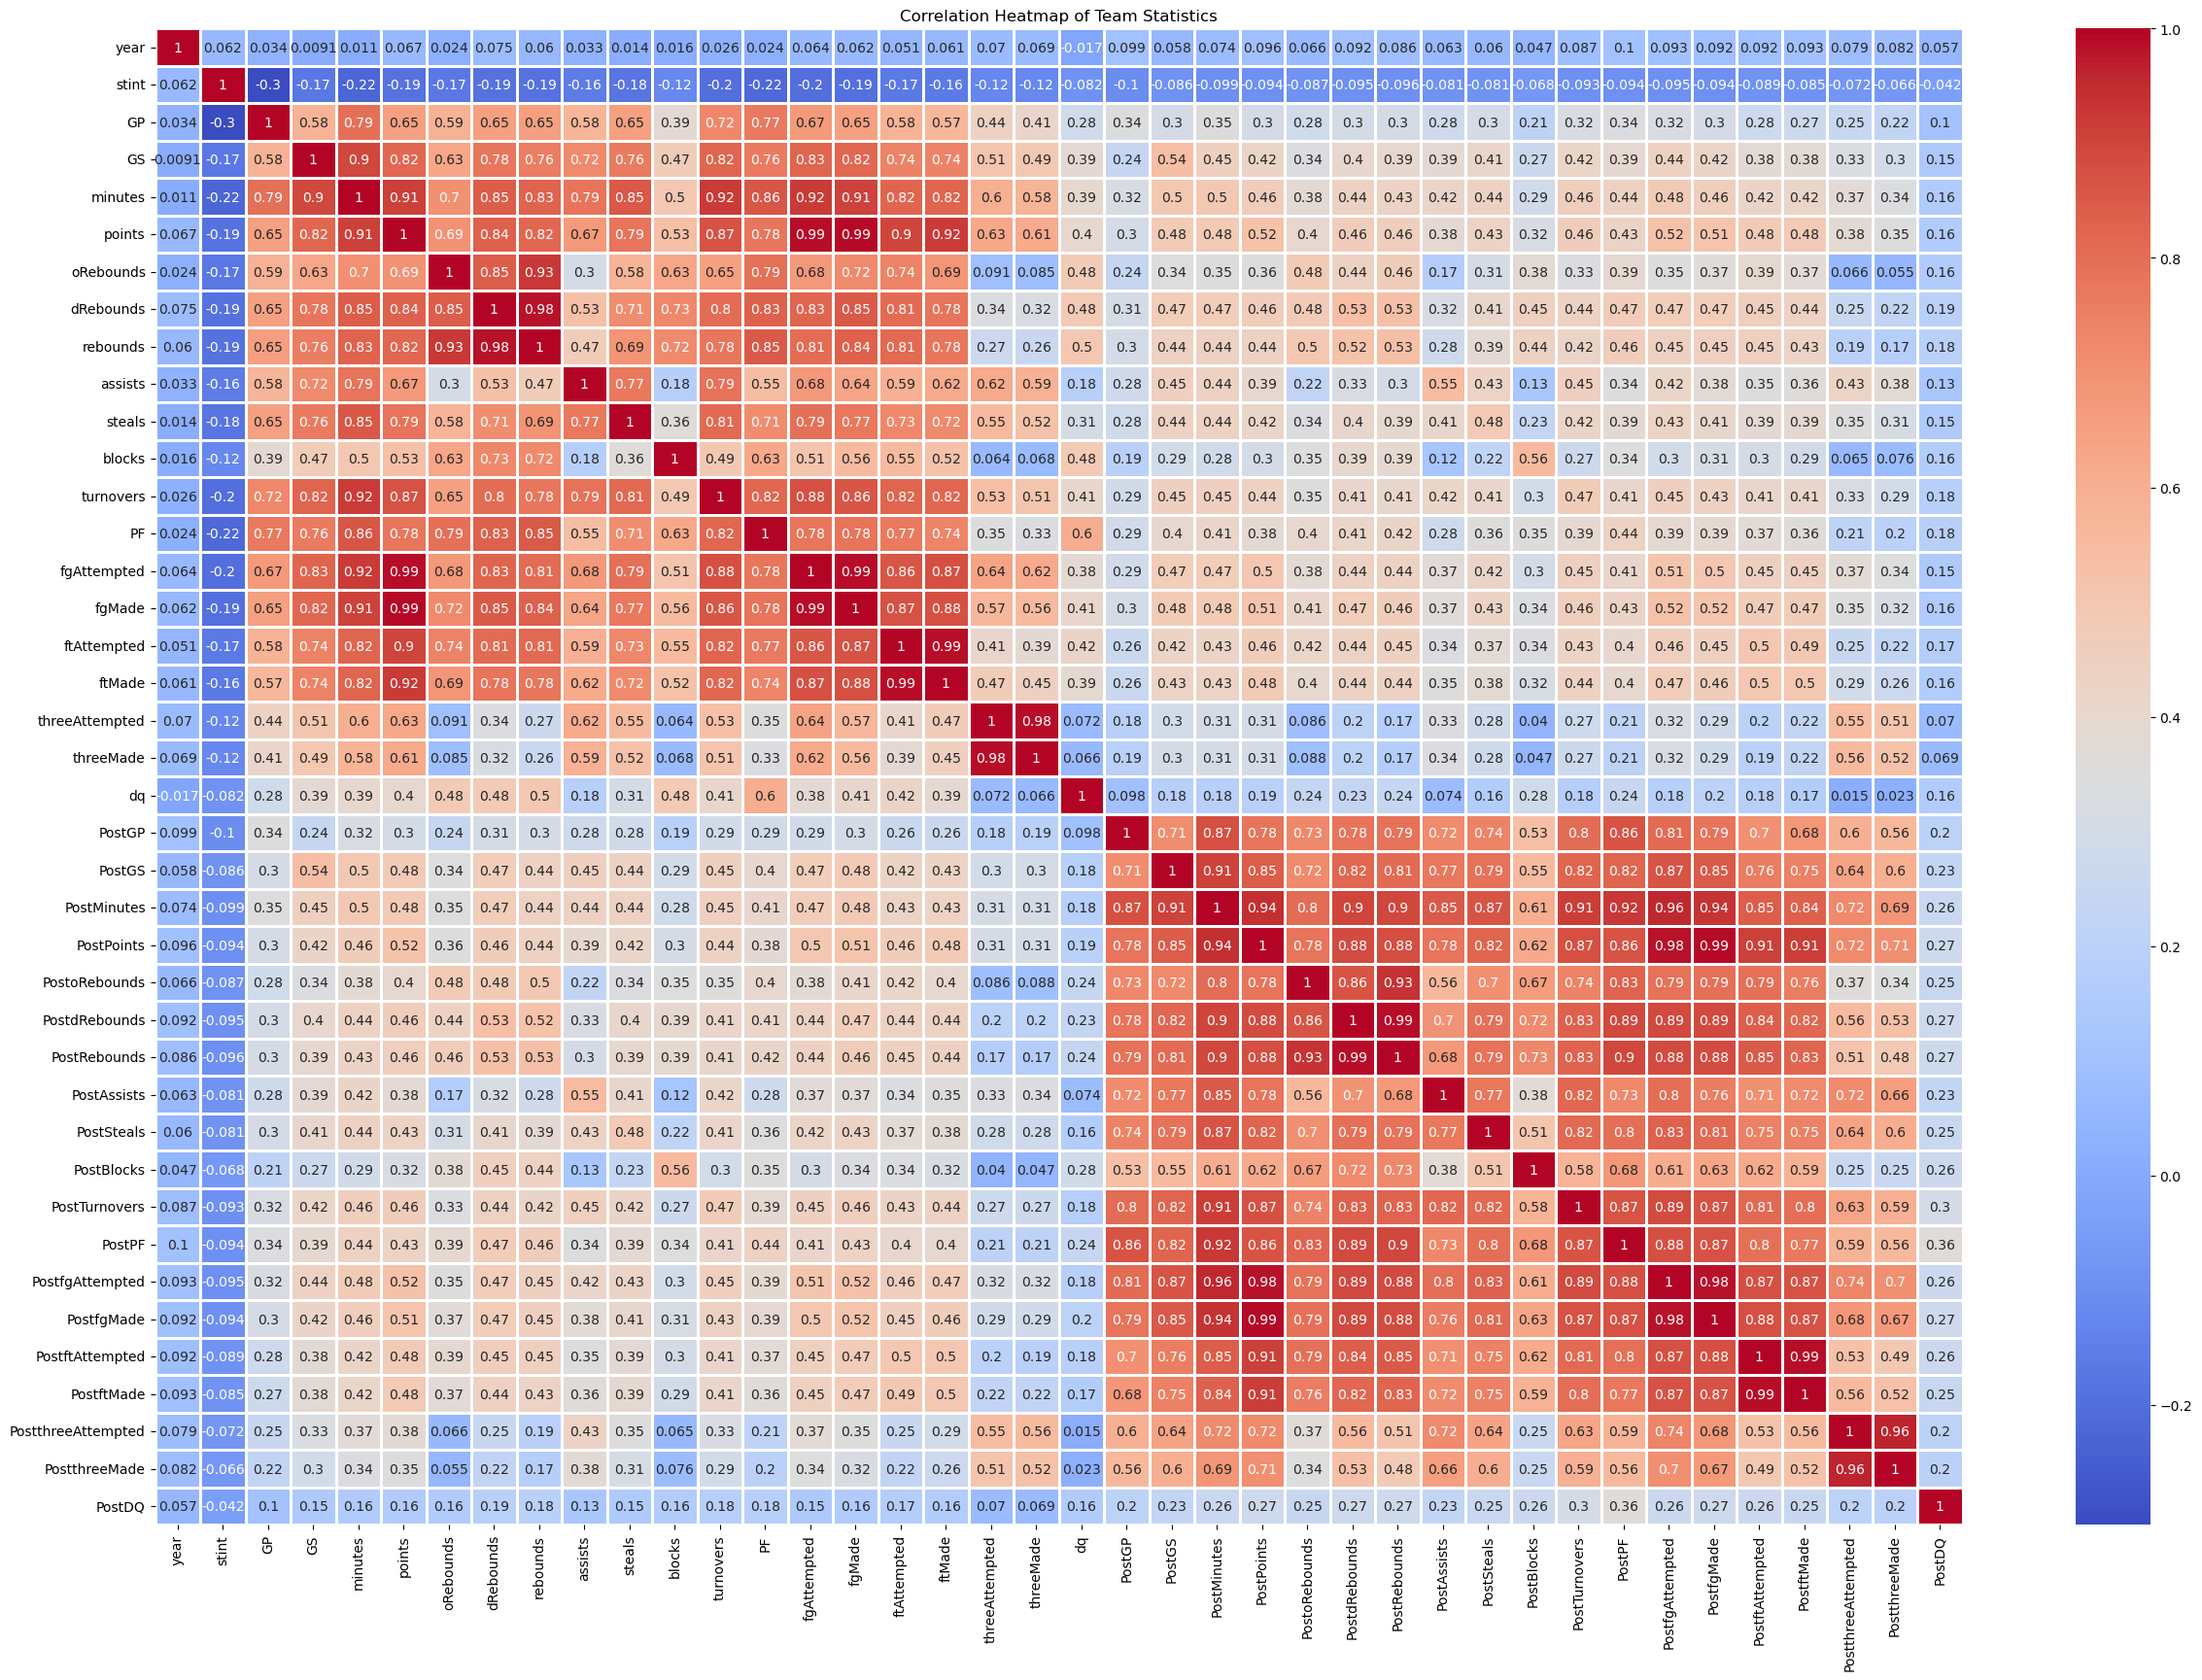

In [66]:

df = pd.read_csv("basketballPlayoffs/players_teams.csv")
df = df.loc[:, (df != 0).any(axis=0)] # Eliminar Noisy Columns (que so têm 0)
data_numeric=df.select_dtypes(['number'])
correlation_matrix = data_numeric.corr()

plt.figure(figsize=(30, 20))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", linewidths=1)
plt.title("Correlation Heatmap of Team Statistics")
plt.show()


In [94]:
"""# VPS Player Value Calculator

# https://www.hudl.com/blog/value-point-system-the-all-in-one-stat-that-keeps-growing

df['FT_Missed'] = df['ftAttempted'] - df['ftMade']
df['FG_Missed'] = df['fgAttempted'] - df['fgMade']

df['VPS'] = (df['points'] + df['rebounds'] + 2 * (df['assists'] + df['steals'] + df['blocks'])) / (
    df['FT_Missed'] + 2 * (df['PF'] + df['turnovers'] + df['FG_Missed']) + 1
)
df['VPS_Per_Minute'] = df['VPS'] / (df['minutes'] + 1) 

# For display purposes, select only relevant columns
df_vps = df[['playerID', 'year', 'tmID', 'VPS', 'VPS_Per_Minute']]


display(df_vps)

df_vps.to_csv('cleaned_datasets/players_teams_cleaned.csv', index=False)"""


# Resorting to EFF
# https://en.wikipedia.org/wiki/Efficiency_(basketball) / https://www.sportsbettingdime.com/guides/how-to/calculate-per/

df['FT_Missed'] = df['ftAttempted'] - df['ftMade']
df['FG_Missed'] = df['fgAttempted'] - df['fgMade']
df['Performance_Per_Game'] = (df['points'] + df['rebounds'] + df['assists'] + df['steals'] + df['blocks'] -df['FG_Missed'] - df['FT_Missed'] - df['turnovers']) / (df['GP'] + 1e-6)  

df_performance = df[['playerID', 'year', 'tmID', 'Performance_Per_Game']]
display(df_performance)
df_performance.to_csv('cleaned_datasets/players_teams_cleaned.csv', index=False)


"""
df_year_1 = df_performance[df_performance['year'] == 1]
# Confirmar se bate com o MVP do ano or close to it
highest_performance_year_1 = df_year_1.loc[df_year_1['Performance_Per_Game'].idxmax()]
print("Highest Performance Per Game in Year 1:")
print(highest_performance_year_1)
"""




,playerID,year,tmID,Performance_Per_Game
0,abrossv01w,2,MIN,12.346153
1,abrossv01w,3,MIN,8.259259
2,abrossv01w,4,MIN,10.133333
3,abrossv01w,5,MIN,6.636363
4,abrossv01w,6,MIN,8.322580
...,...,...,...,...
1871,zakalok01w,3,PHO,-0.200000
1872,zarafr01w,6,SEA,2.970588
1873,zellosh01w,10,DET,9.882353
1874,zirkozu01w,4,WAS,1.666666


'\ndf_year_1 = df_performance[df_performance[\'year\'] == 1]\n# Confirmar se bate com o MVP do ano or close to it\nhighest_performance_year_1 = df_year_1.loc[df_year_1[\'Performance_Per_Game\'].idxmax()]\nprint("Highest Performance Per Game in Year 1:")\nprint(highest_performance_year_1)\n'

In [30]:

df = pd.read_csv("basketballPlayoffs/teams.csv")
df = df.drop(columns=['lgID', 'seeded'])
df.to_csv("cleaned_datasets/teams_cleaned.csv", index=False)


